<a href="https://colab.research.google.com/github/subhajitnaskarns-prog/video_game_hakuda/blob/main/Video_game_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Libraries**

In [ ]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split


**Dataset Upload**

In [ ]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/Dataset/vgsales.csv')


Mounted at /content/drive


**Print 5 rows**

In [ ]:

print("First 5 rows: ")
print(df.head())


First 5 rows: 
   Rank                      Name Platform    Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3            Mario Kart Wii      Wii  2008.0        Racing  Nintendo   
3     4         Wii Sports Resort      Wii  2009.0        Sports  Nintendo   
4     5  Pokemon Red/Pokemon Blue       GB  1996.0  Role-Playing  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58      6.81         0.77         40.24  
2     15.85     12.88      3.79         3.31         35.82  
3     15.75     11.01      3.28         2.96         33.00  
4     11.27      8.89     10.22         1.00         31.37  


**Last 5 Rows**

In [ ]:
print(df.tail())

        Rank                                              Name Platform  \
16593  16596                Woody Woodpecker in Crazy Castle 5      GBA   
16594  16597                     Men in Black II: Alien Escape       GC   
16595  16598  SCORE International Baja 1000: The Official Game      PS2   
16596  16599                                        Know How 2       DS   
16597  16600                                  Spirits & Spells      GBA   

         Year     Genre   Publisher  NA_Sales  EU_Sales  JP_Sales  \
16593  2002.0  Platform       Kemco      0.01      0.00       0.0   
16594  2003.0   Shooter  Infogrames      0.01      0.00       0.0   
16595  2008.0    Racing  Activision      0.00      0.00       0.0   
16596  2010.0    Puzzle    7G//AMES      0.00      0.01       0.0   
16597  2003.0  Platform     Wanadoo      0.01      0.00       0.0   

       Other_Sales  Global_Sales  
16593          0.0          0.01  
16594          0.0          0.01  
16595          0.0          0

**Size of Dataset**

In [ ]:
print("Shape of dataset: ",df.shape)
print("Number of rows: ",df.shape[0])


Shape of dataset:  (16598, 11)
Number of rows:  16598


**Dataset Information**

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB
None


**Statistical Summary**

In [ ]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


**Types of columns**

In [ ]:
print(df.dtypes)

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object


**All columns name**

In [ ]:
print(df.columns)

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')


**Statistical Summary**

In [ ]:
df.describe(include="all")

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16598,16598,16327.000000,16598,16540,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
unique,NaN,11493,31,NaN,12,578,NaN,NaN,NaN,NaN,NaN
top,NaN,Need for Speed: Most Wanted,DS,NaN,Action,Electronic Arts,NaN,NaN,NaN,NaN,NaN
freq,NaN,12,2163,NaN,3316,1351,NaN,NaN,NaN,NaN,NaN
mean,8300.605254,NaN,NaN,2006.406443,NaN,NaN,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,NaN,NaN,5.828981,NaN,NaN,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,NaN,NaN,1980.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,NaN,NaN,2003.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,NaN,NaN,2007.000000,NaN,NaN,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,NaN,NaN,2010.000000,NaN,NaN,0.240000,0.110000,0.040000,0.040000,0.470000


**Missing Values Check**

In [ ]:
df.isnull().sum().sum()

np.int64(329)

**Duplicate Check**

In [ ]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  0


**Missing Values Check**

In [ ]:
df.isnull().sum()

,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


**Duplicate Check**

In [ ]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  0


**Omit Duplicate Values**

In [ ]:
print("Original shape: ",df.shape)
df_drop = df.dropna()
print("Shape after removing missing values: ", df_drop.shape)

Original shape:  (16598, 11)
Shape after removing missing values:  (16291, 11)


**Check Missing Value**

In [ ]:
print("\nMissing values after dropna():")
print(df_drop.isnull().sum())



Missing values after dropna():
Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


In [ ]:
df.isnull().sum()

,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


**Statiscal Outlier**

In [ ]:
# Calculate IQR for 'Year'
Q1 = df["Year"].quantile(0.25)
Q3 = df["Year"].quantile(0.75)
IQR = Q3 - Q1

# Define upper and lower limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# (Optional) Calculate original outliers to fix the second NameError on print(original_outliers)
original_outliers = df[(df["Year"] < lower_limit) | (df["Year"] > upper_limit)].shape[0]

**Remove Outliers**

In [ ]:
#Store original shape
original_shape = df.shape

#remove outliers
df = df[
    (df["Year"] >= lower_limit) &
    (df["Year"] <= upper_limit)
]
#store new shape
new_shape = df.shape
print("\nOriginal Outliers: ")
print(original_outliers)

print("\nDataset Shape Before Treatment: ", original_shape)
print("Dataset Shape After Treatment: ", new_shape)



Original Outliers: 
305

Dataset Shape Before Treatment:  (16598, 11)
Dataset Shape After Treatment:  (16022, 11)


**Data Cleaning**

In [ ]:
print("\nNumber of Rows Removed: ",
      original_shape[0] - new_shape[0])

print("\nUpdated Dataset:")
print(df)



Number of Rows Removed:  576

Updated Dataset:
        Rank                                              Name Platform  \
0          1                                        Wii Sports      Wii   
2          3                                    Mario Kart Wii      Wii   
3          4                                 Wii Sports Resort      Wii   
4          5                          Pokemon Red/Pokemon Blue       GB   
6          7                             New Super Mario Bros.       DS   
...      ...                                               ...      ...   
16593  16596                Woody Woodpecker in Crazy Castle 5      GBA   
16594  16597                     Men in Black II: Alien Escape       GC   
16595  16598  SCORE International Baja 1000: The Official Game      PS2   
16596  16599                                        Know How 2       DS   
16597  16600                                  Spirits & Spells      GBA   

         Year         Genre   Publisher  NA_Sales  

**Check Duplicate Rows**

In [ ]:
print(df.duplicated().sum())

0


**Clean Dataset & Duplicates Remove**

In [ ]:
df= df.drop_duplicates()
print(df.dtypes)
print(df["Name"].unique())
print(df["Platform"].unique())
print(df["Genre"].unique())

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object
['Wii Sports' 'Mario Kart Wii' 'Wii Sports Resort' ... 'Plushees'
 'Woody Woodpecker in Crazy Castle 5' 'Know How 2']
['Wii' 'GB' 'DS' 'X360' 'PS3' 'PS2' 'GBA' '3DS' 'PS4' 'N64' 'PS' 'SNES'
 'XB' 'PC' 'PSP' 'XOne' 'GC' 'WiiU' 'DC' 'PSV' 'SAT' 'GEN' 'NES' 'SCD'
 'WS' 'NG' 'TG16' '3DO' 'PCFX']
['Sports' 'Racing' 'Role-Playing' 'Platform' 'Misc' 'Simulation' 'Action'
 'Puzzle' 'Shooter' 'Fighting' 'Adventure' 'Strategy']


In [ ]:
df= df.drop_duplicates()
print(df.dtypes)
print(df["Name"].unique())
print(df["Platform"].unique())
print(df["Genre"].unique())

print(df["Name"].value_counts())
print(df["Platform"].value_counts())
print(df["Genre"].value_counts())

#label encoding
le = LabelEncoder()
df["Platform_encoded"] = le.fit_transform(df["Platform"])
print(df[["Platform","Platform_encoded"]].head())


Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object
['Wii Sports' 'Mario Kart Wii' 'Wii Sports Resort' ... 'Plushees'
 'Woody Woodpecker in Crazy Castle 5' 'Know How 2']
['Wii' 'GB' 'DS' 'X360' 'PS3' 'PS2' 'GBA' '3DS' 'PS4' 'N64' 'PS' 'SNES'
 'XB' 'PC' 'PSP' 'XOne' 'GC' 'WiiU' 'DC' 'PSV' 'SAT' 'GEN' 'NES' 'SCD'
 'WS' 'NG' 'TG16' '3DO' 'PCFX']
['Sports' 'Racing' 'Role-Playing' 'Platform' 'Misc' 'Simulation' 'Action'
 'Puzzle' 'Shooter' 'Fighting' 'Adventure' 'Strategy']
Name
Need for Speed: Most Wanted                           12
FIFA 14                                                9
Ratatouille                                            9
LEGO Marvel Super Heroes                               9
Monopoly                                               8
          

In [ ]:
#Label Encoding or categorical encoding
df["Name_encoded"] = le.fit_transform(df["Name"])
print(df[["Name", "Name_encoded"]].head())

df["Genre_encoded"] = le.fit_transform(df["Genre"])
print(df[["Genre", "Genre_encoded"]].head())


                       Name  Name_encoded
0                Wii Sports         10641
2            Mario Kart Wii          5373
3         Wii Sports Resort         10643
4  Pokemon Red/Pokemon Blue          7100
6     New Super Mario Bros.          6492
          Genre  Genre_encoded
0        Sports             10
2        Racing              6
3        Sports             10
4  Role-Playing              7
6      Platform              4


In [ ]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Platform_encoded,Name_encoded,Genre_encoded
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,24,10641,10
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,24,5373,6
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,24,10643,10
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,4,7100,7
6,7,New Super Mario Bros.,DS,2006.0,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01,3,6492,4


**Normalization**

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Normalization
scaler = MinMaxScaler()
df["Year_normalized"] = scaler.fit_transform(
    df[["Year"]]
)
print(
    df[
        ["Year", "Year_normalized"]
    ].head()
)

     Year  Year_normalized
0  2006.0         0.481481
2  2008.0         0.555556
3  2009.0         0.592593
4  1996.0         0.111111
6  2006.0         0.481481


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Normalization
scaler = MinMaxScaler()
df["JP_Sales_normalized"] = scaler.fit_transform(
    df[["JP_Sales"]]
)
print(
    df[
        ["JP_Sales", "JP_Sales_normalized"]
    ].head()
)

   JP_Sales  JP_Sales_normalized
0      3.77             0.368885
2      3.79             0.370841
3      3.28             0.320939
4     10.22             1.000000
6      6.50             0.636008


**Standarization**

In [ ]:
from sklearn.preprocessing import StandardScaler

#standarization
scaler = StandardScaler()
df["JP_Sales_standardized"] = scaler.fit_transform(
     df[["JP_Sales"]]
)
print(
     df[
         ["JP_Sales", "JP_Sales_standardized"]
     ].head()
)

   JP_Sales  JP_Sales_standardized
0      3.77              13.017112
2      3.79              13.087477
3      3.28              11.293175
4     10.22              35.709756
6      6.50              22.621906


In [ ]:
from sklearn.preprocessing import StandardScaler

#standarization
scaler = StandardScaler()
df["Year_standardized"] = scaler.fit_transform(
     df[["Year"]]
)
print(
     df[
         ["Year", "Year_standardized"]
     ].head()
)

     Year  Year_standardized
0  2006.0          -0.153231
2  2008.0           0.235444
3  2009.0           0.429781
4  1996.0          -2.096601
6  2006.0          -0.153231


In [ ]:
#Numerical features select & check
features = [
    'Year',
    'JP_Sales',
    'Rank',
    'Platform',
    'Publisher',
    'Other_Sales',
    'Global_Sales',
    'EU_Sales',
    'NA_Sales'
]

df[features].head()

,Year,JP_Sales,Rank,Platform,Publisher,Other_Sales,Global_Sales,EU_Sales,NA_Sales
0,2006.0,3.77,1,Wii,Nintendo,8.46,82.74,29.02,41.49
2,2008.0,3.79,3,Wii,Nintendo,3.31,35.82,12.88,15.85
3,2009.0,3.28,4,Wii,Nintendo,2.96,33.00,11.01,15.75
4,1996.0,10.22,5,GB,Nintendo,1.00,31.37,8.89,11.27
6,2006.0,6.50,7,DS,Nintendo,2.90,30.01,9.23,11.38


**Target Value**

In [ ]:
# Create Sales Category based on Global_Sales
def sales_category(sales):
  if sales >= 40.0:
    return "High Sales"
  elif sales >= 20.0:
    return "Medium Sales"
  else:
    return "Low Sales"


# Apply the function to Global_Sales column
df["global_sales_category"] = df["Global_Sales"].apply(sales_category)

# Check the result
df[["Global_Sales", "global_sales_category"]].head(20)

,Global_Sales,global_sales_category
0,82.74,High Sales
2,35.82,Medium Sales
3,33.00,Medium Sales
4,31.37,Medium Sales
6,30.01,Medium Sales
7,29.02,Medium Sales
8,28.62,Medium Sales
10,24.76,Medium Sales
11,23.42,Medium Sales
12,23.10,Medium Sales


**EDA**

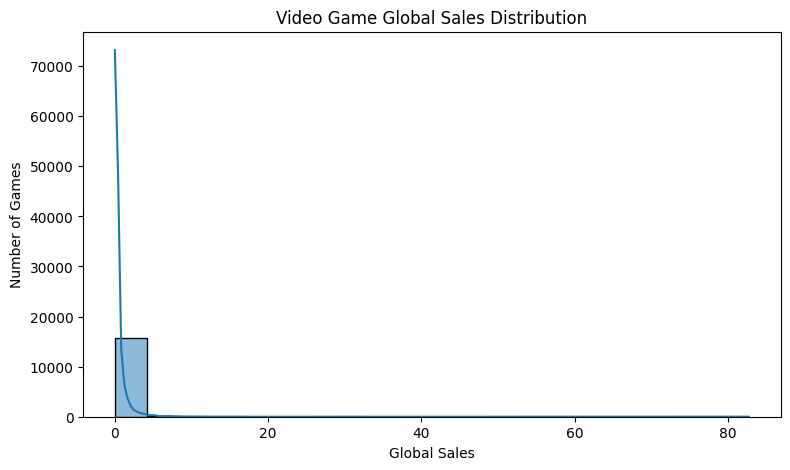

In [ ]:
# EDA Global Sales Distribution
plt.figure(figsize=(9, 5))

sns.histplot(df["Global_Sales"], bins=20, kde=True)

plt.title("Video Game Global Sales Distribution")
plt.xlabel("Global Sales")
plt.ylabel("Number of Games")
plt.show()

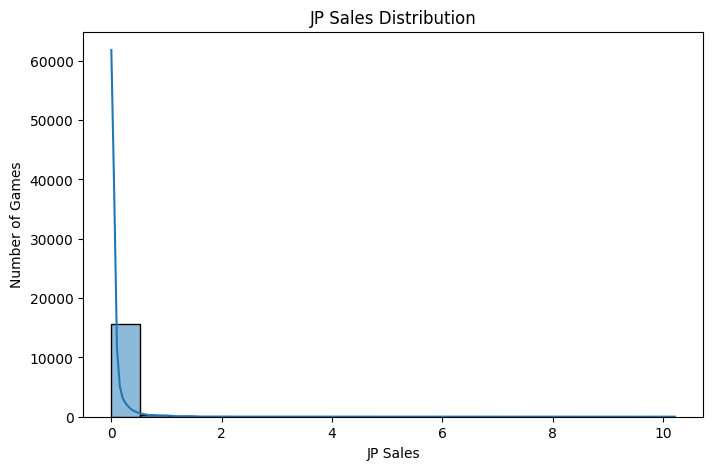

In [ ]:
# EDA
plt.figure(figsize=(8, 5))

sns.histplot(df["JP_Sales"], bins=20, kde=True)

plt.title("JP Sales Distribution")
plt.xlabel("JP Sales")
plt.ylabel("Number of Games")
plt.show()

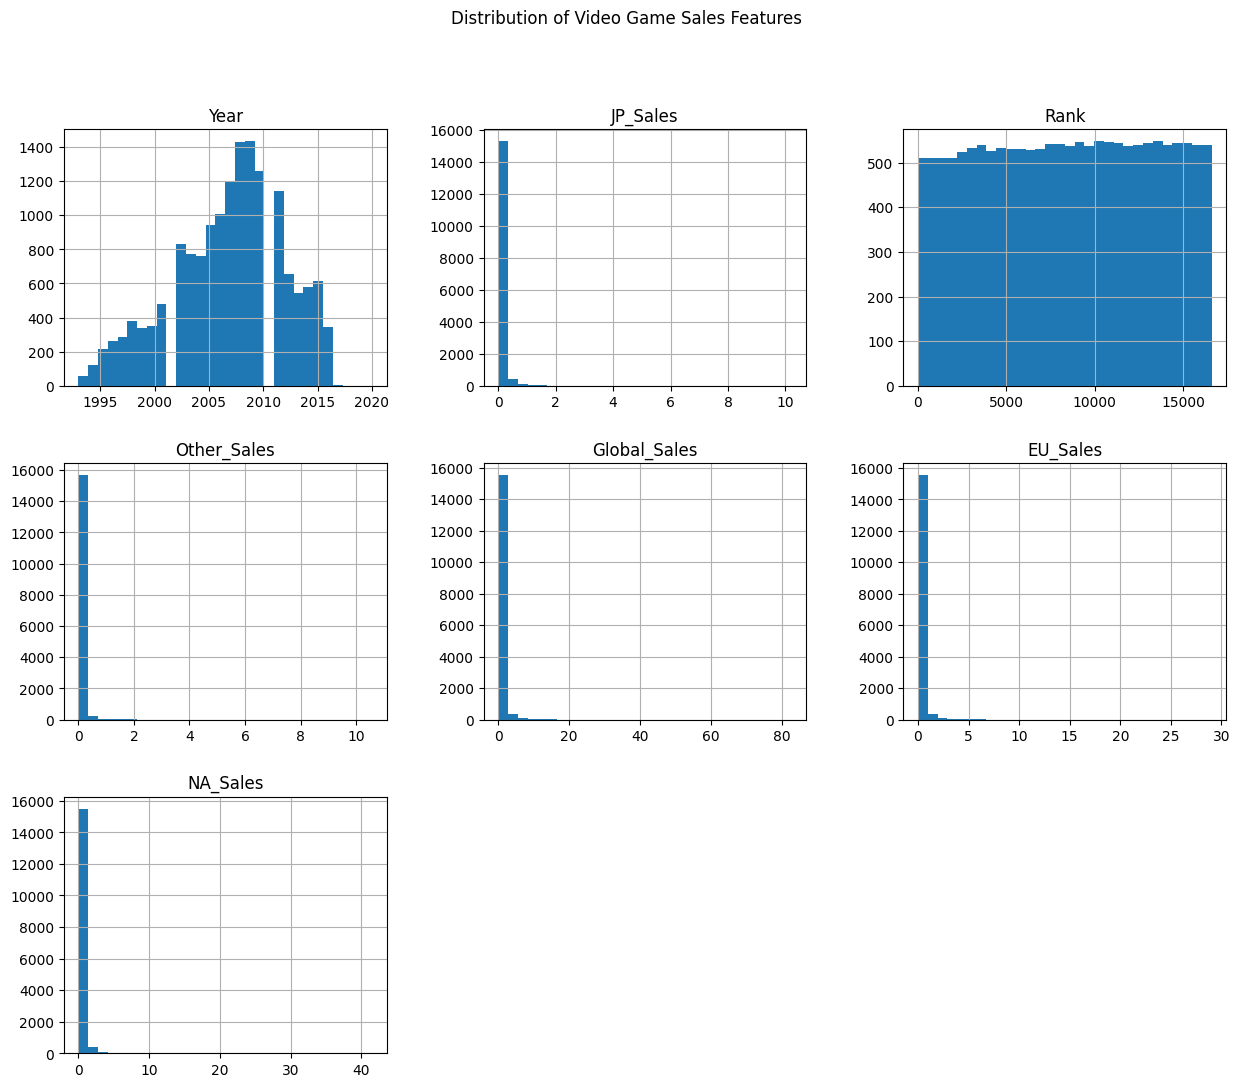

In [ ]:
# Feature Distribution
df[features].hist(figsize=(15, 12), bins=30)

plt.suptitle("Distribution of Video Game Sales Features")

plt.show()

**Data Preprocessing**

In [ ]:
#data pre processing
from sklearn.preprocessing import MinMaxScaler

numerical_features = [
    "Rank",
    "Year",
    "JP_Sales",
    "EU_Sales",
    "NA_Sales",
    "Other_Sales",
    "Global_Sales",
]

scaler = MinMaxScaler()
df_normalized = df.copy()

df_normalized[numerical_features] = scaler.fit_transform(
    df_normalized[numerical_features]
)

In [ ]:
print( df_normalized[features].head())

       Year  JP_Sales      Rank Platform Publisher  Other_Sales  Global_Sales  \
0  0.481481  0.368885  0.000000      Wii  Nintendo     0.800378      1.000000   
2  0.555556  0.370841  0.000120      Wii  Nintendo     0.313150      0.432854   
3  0.592593  0.320939  0.000181      Wii  Nintendo     0.280038      0.398767   
4  0.111111  1.000000  0.000241       GB  Nintendo     0.094607      0.379064   
6  0.481481  0.636008  0.000361       DS  Nintendo     0.274361      0.362625   

   EU_Sales  NA_Sales  
0  1.000000  1.000000  
2  0.443832  0.382020  
3  0.379394  0.379610  
4  0.306340  0.271632  
6  0.318057  0.274283  


In [ ]:
from sklearn.preprocessing import StandardScaler

numerical_features = [
    "Rank",
    "Year",
    "JP_Sales",
    "EU_Sales",
    "NA_Sales",
    "Other_Sales",
    "Global_Sales",
]

scaler = StandardScaler()
df_standardized = df.copy()

df_standardized[numerical_features] = scaler.fit_transform(
    df_standardized[numerical_features]
)

print(df_standardized[numerical_features].head())

       Rank      Year   JP_Sales   EU_Sales   NA_Sales  Other_Sales  \
0 -1.756001 -0.153231  13.017112  56.658076  57.376296    44.050327   
2 -1.755582  0.235444  13.087477  24.986267  21.702844    17.080000   
3 -1.755372  0.429781  11.293175  21.316732  21.563712    15.247065   
4 -1.755163 -2.096601  35.709756  17.156619  15.330597     4.982630   
6 -1.754744 -0.153231  22.621906  17.823807  15.483642    14.932848   

   Global_Sales  
0     55.658941  
2     23.897479  
3     21.988542  
4     20.885149  
6     19.964527  


**Data Splitting**

In [ ]:
#data splitting

X = df[["Year", "Rank", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]]
y = df["Global_Sales"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
   X,
   y,
   test_size=0.20,
   random_state=42
)

print("Training data: ",X_train.shape)

print("Testing data: ", X_test.shape)

Training data:  (12817, 6)
Testing data:  (3205, 6)


In [ ]:
print(X_train.head())

         Year   Rank  NA_Sales  EU_Sales  JP_Sales  Other_Sales
10542  2003.0  10544      0.08      0.02       0.0         0.00
5034   2009.0   5036      0.13      0.21       0.0         0.04
12408  2005.0  12410      0.00      0.05       0.0         0.01
12655  2009.0  12657      0.00      0.05       0.0         0.01
3298   2011.0   3300      0.50      0.07       0.0         0.04


**Feature Selection**

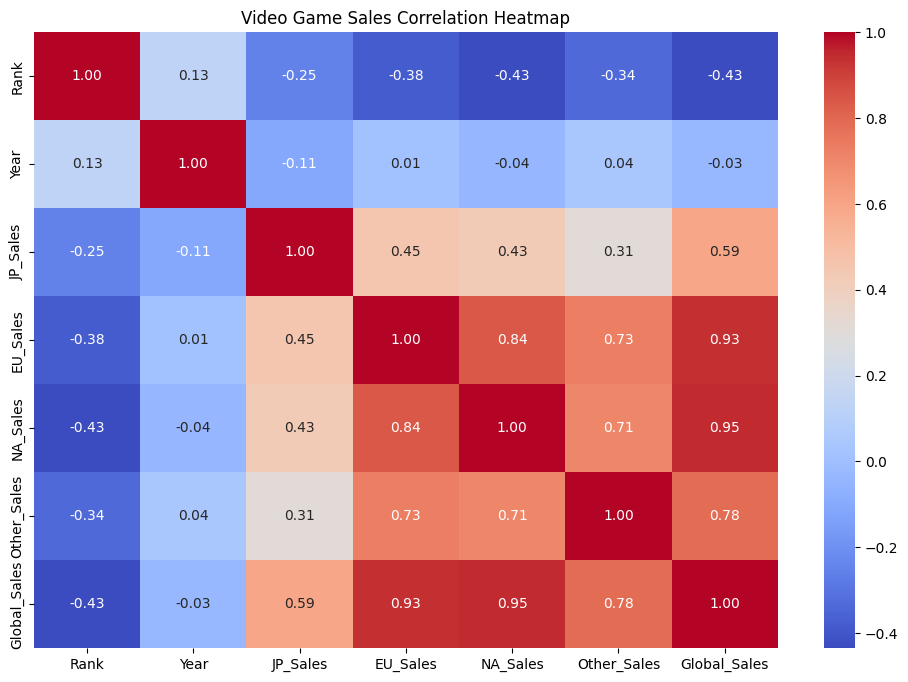

In [ ]:
# Feature selation
#Correlation Heatmap

plt.figure(figsize=(12, 8))


correlation = df[numerical_features].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Video Game Sales Correlation Heatmap")

plt.show()

**EDA**

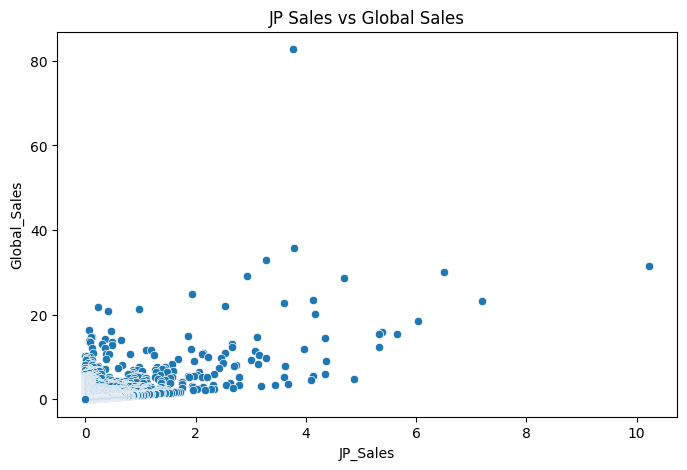

In [ ]:
#EDA
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="JP_Sales",
    y="Global_Sales",
)

plt.title("JP Sales vs Global Sales")
plt.show()

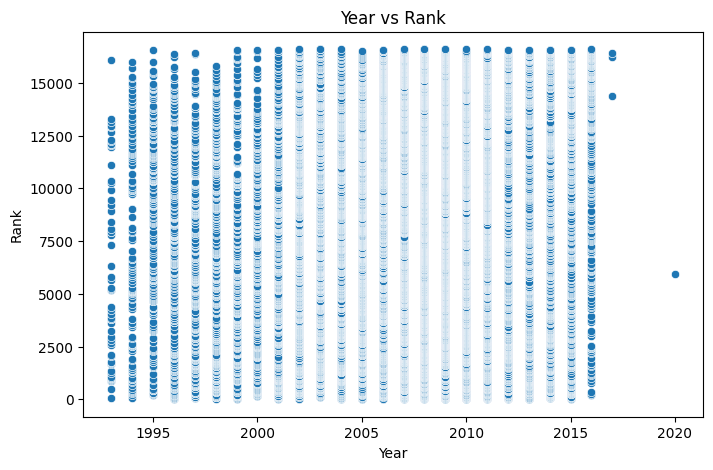

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Year",
    y="Rank",
)

plt.title("Year vs Rank")
plt.show()

**Model Preparation**

In [ ]:
#model prepartion


# 1. Features list define
features = ["Year", "Rank", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]

X = df[features]
y = df[
    "global_sales_category"
]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (16022, 6)
y shape: (16022,)


In [ ]:
#Train-Test-split & checking
X_train, X_test, y_train, y_test = train_test_split(
   X,
   y,
   test_size=0.20,
   random_state=42

)

print("Training data: ",X_train.shape)

print("Testing data: ", X_test.shape)


Training data:  (12817, 6)
Testing data:  (3205, 6)


**Feature Scaling**

In [ ]:
# Feature scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (12817, 6)
Scaled testing data: (3205, 6)


In [ ]:
#Logistic Regression & Prediction
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("===== Logistic Regression =====")
print("Model trained successfully!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Predictions generated:", len(y_pred_logistic))
print("First 10 predictions:")
print(y_pred_logistic[:10])

===== Logistic Regression =====
Model trained successfully!
Training data shape: (12817, 6)
Testing data shape: (3205, 6)
Predictions generated: 3205
First 10 predictions:
['Low Sales' 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales'
 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales']


**Model Training**

In [ ]:
#Model training


# Decision Tree & Prediction
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)
decision_tree.fit(X_train, y_train)
y_pred_tree = decision_tree.predict(X_test)
print("===== Decision Tree =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_tree))
print("First 10 predictions:")
print(y_pred_tree[:10])

===== Decision Tree =====
Model trained successfully!
Training data shape: (12817, 6)
Testing data shape: (3205, 6)
Predictions generated: 3205
First 10 predictions:
['Low Sales' 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales'
 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales']


In [ ]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

print("===== Random Forest =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_rf))
print("First 10 predictions:")
print(y_pred_rf[:10])

===== Random Forest =====
Model trained successfully!
Training data shape: (12817, 6)
Testing data shape: (3205, 6)
Predictions generated: 3205
First 10 predictions:
['Low Sales' 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales'
 'Low Sales' 'Low Sales' 'Low Sales' 'Low Sales']


**Model Evaluation**

In [ ]:
#model evaluation


# Model Evaluation Function
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    print("=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    return accuracy, precision, recall, f1

In [ ]:
#Evaluate Logistic Regression
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.9997
Precision: 0.9994
Recall   : 0.9997
F1 Score : 0.9995

Classification Report:
              precision    recall  f1-score   support

  High Sales       0.00      0.00      0.00         1
   Low Sales       1.00      1.00      1.00      3200
Medium Sales       0.80      1.00      0.89         4

    accuracy                           1.00      3205
   macro avg       0.60      0.67      0.63      3205
weighted avg       1.00      1.00      1.00      3205



In [ ]:
# Evaluate Decision Tree
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.9997
Precision: 0.9994
Recall   : 0.9997
F1 Score : 0.9995

Classification Report:
              precision    recall  f1-score   support

  High Sales       0.00      0.00      0.00         1
   Low Sales       1.00      1.00      1.00      3200
Medium Sales       0.80      1.00      0.89         4

    accuracy                           1.00      3205
   macro avg       0.60      0.67      0.63      3205
weighted avg       1.00      1.00      1.00      3205



In [ ]:
#Evaluate Random Forest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf
)

Random Forest
Accuracy : 0.9997
Precision: 0.9994
Recall   : 0.9997
F1 Score : 0.9995

Classification Report:
              precision    recall  f1-score   support

  High Sales       0.00      0.00      0.00         1
   Low Sales       1.00      1.00      1.00      3200
Medium Sales       0.80      1.00      0.89         4

    accuracy                           1.00      3205
   macro avg       0.60      0.67      0.63      3205
weighted avg       1.00      1.00      1.00      3205



**Model Compare**

In [ ]:
#model compare

# Model Comparison
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        logistic_results[0],
        rf_results[0]
    ],
    'Precision': [
        logistic_results[1],
        rf_results[1]
    ],
    'Recall': [
        logistic_results[2],
        rf_results[2]
    ],
    'F1 Score': [
        logistic_results[3],
        rf_results[3]
    ]
})

print("===== Model Performance Comparison =====")
display(results)

===== Model Performance Comparison =====


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.999688,0.999438,0.999688,0.999549
1,Random Forest,0.999688,0.999438,0.999688,0.999549


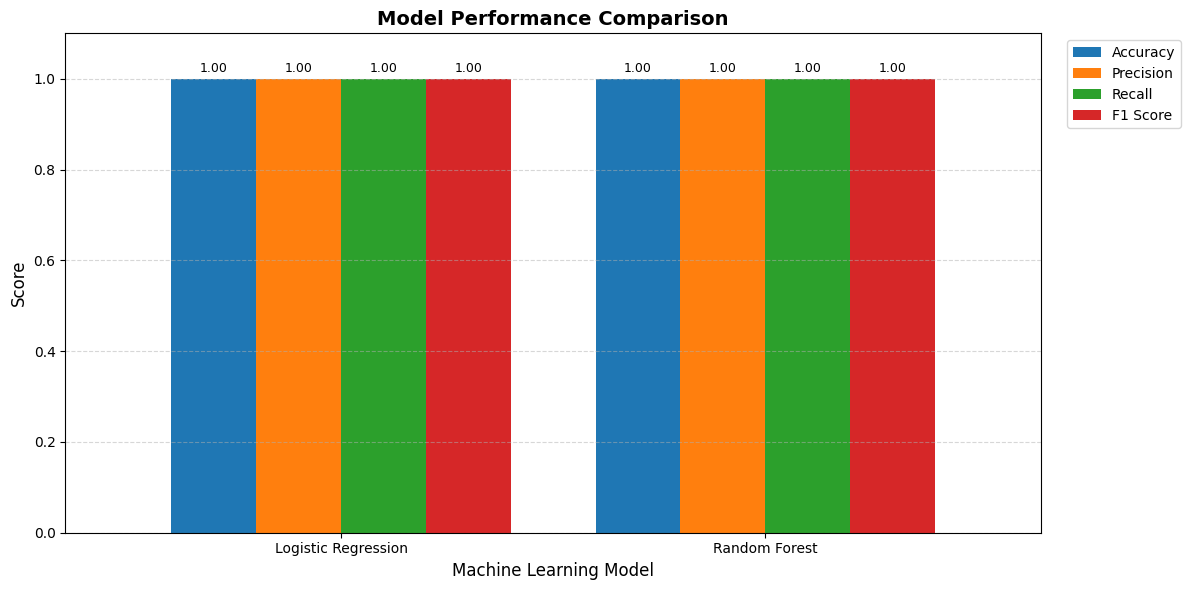

In [ ]:
# Model Comparison Graph
import matplotlib.pyplot as plt

# Plot grouped bar chart
ax = results.set_index("Model").plot(kind="bar", figsize=(12, 6), width=0.8)

plt.title("Model Performance Comparison", fontsize=14, fontweight="bold")
plt.ylabel("Score", fontsize=12)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylim(0, 1.1)  # Raised slightly to give room for labels above bars
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add exact score values on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

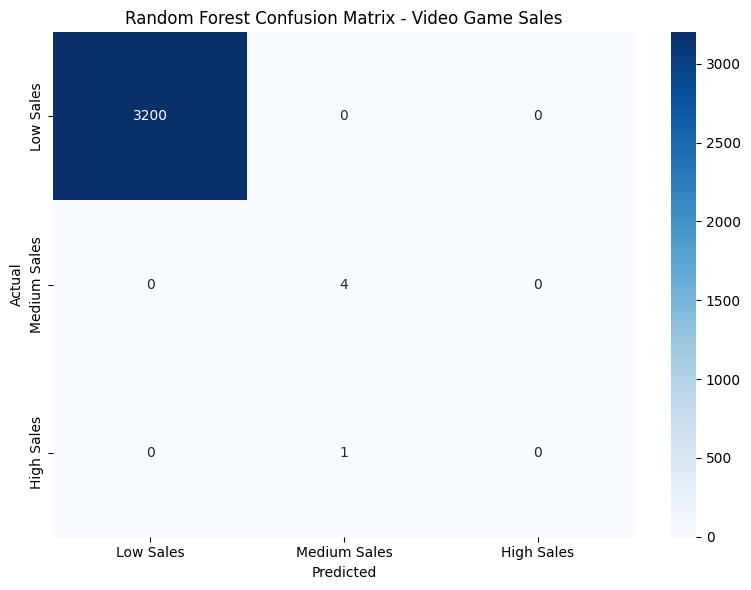

In [ ]:
#Confusion Matrix
# Confusion Matrix for Video Game Sales Classification
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[
        "Low Sales",
        "Medium Sales",
        "High Sales",
    ],
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Sales", "Medium Sales", "High Sales"],
    yticklabels=["Low Sales", "Medium Sales", "High Sales"],
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix - Video Game Sales")

plt.tight_layout()
plt.show()

**Model Interpretation/Feature Analysis**

In [ ]:
#Model Interpretion

#Feature Independence
#1. Calculate Feature Importance
import pandas as pd

importance = pd.DataFrame({
    'Feature': features,
    'Importance': random_forest.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("===== Feature Importance =====")
display(importance)

===== Feature Importance =====


,Feature,Importance
1,Rank,0.394367
3,EU_Sales,0.239442
2,NA_Sales,0.165029
5,Other_Sales,0.142017
4,JP_Sales,0.050159
0,Year,0.008986


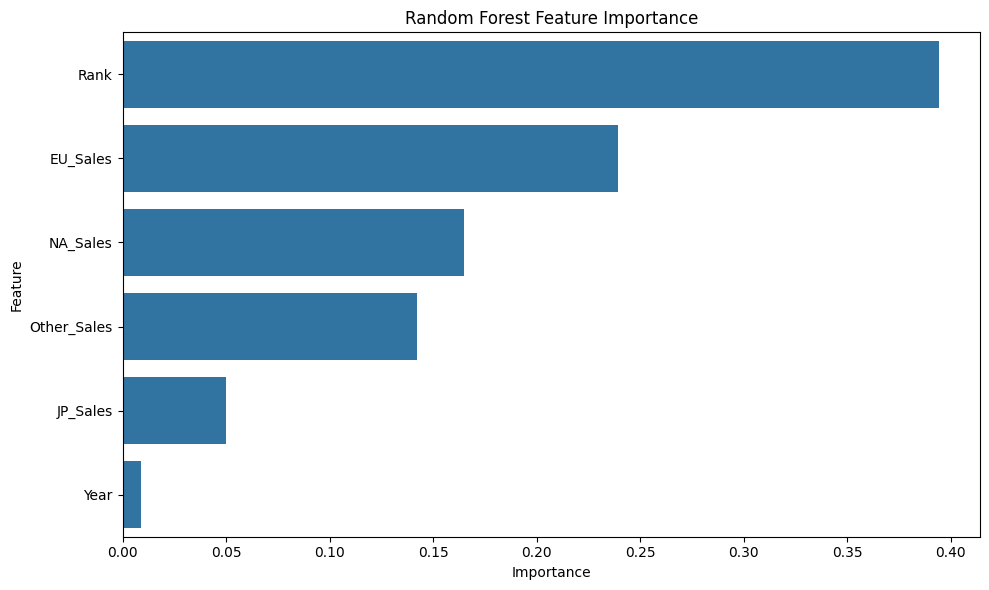

In [ ]:
#2. Feature Importance Graph
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

**Model Prediction**

In [ ]:
#model prediction

# Create New Video Game Data
new_game = pd.DataFrame(
    {
        "Year": [2026.0],
        "Rank": [10],
        "NA_Sales": [1.50],
        "EU_Sales": [1.20],
        "JP_Sales": [0.80],
        "Other_Sales": [0.30],
    }
)

print("===== New Video Game Features =====")
display(new_game)

===== New Video Game Features =====


,Year,Rank,NA_Sales,EU_Sales,JP_Sales,Other_Sales
0,2026.0,10,1.5,1.2,0.8,0.3


In [ ]:
# Prediction for Video Game Sales Category
prediction = random_forest.predict(new_game)

print("===== Prediction Result =====")
print("Predicted Video Game Sales Category:", prediction[0])

===== Prediction Result =====
Predicted Video Game Sales Category: Medium Sales


In [ ]:
# Prediction Probability for Video Game Sales
probability = random_forest.predict_proba(new_game)

print("===== Prediction Probabilities =====")

for category, prob in zip(random_forest.classes_, probability[0]):
  print(f"{category}: {prob * 100:.2f}%")

===== Prediction Probabilities =====
Low Sales: 48.00%
Medium Sales: 52.00%
